# Projekt IUM (zadanie 5)
#### Michał Jakomulski, Jakub Jóźwiak


### Problem biznesowy
Na podstawie analizy przedstawionego problemu ustaliliśmy, że naszym zasadniczym zadaniem jest stworzenie algorytmu generującego popularne wśród użytkowników playlisty. Popularność zgodnie z naszymi założeniami to liczba odtworzeń playlisty, w ramach których użytkownik przesłuchał co najmniej 50% playlisty (tzn. jeśli utwory na playliście mają łączną długość 40 minut, to odtworzeniem będzie sytuacja, w ramach której użytkownik słuchał playlisty przez co najmniej 20 minut). Playlisty będą ogólnodostępne dla użytkowników serwisu Pozytywka. Ich liczba będzie określana na podstawie liczby potencjalnie popularnych kategorii, które zostaną wyznaczone w ramach realizacji zadania modelowania. Generowanie playlist będzie się odbywać cyklicznie. Wstępnie przewidujemy generowanie ich raz na miesiąc, natomiast częstotliwość generowania może ulec zmianie w zależności od możliwości dostarczania zaktualizowanych danych o odsłuchaniach playlisty (próby generowania nowych playlist na podstawie starych, nieaktualnych danych nie będą przynosiły oczekiwanych rezultatów) oraz tempa zmian preferencji użytkowników (tzn. proponowane playlisty przestają być popularne - liczba odtworzeń spada poniżej określonego w ramach realizacji zadania poziomu).

### Zadanie modelowania i jego założenia
#### Zadanie modelowania
Nasz problem biznesowy podzieliliśmy na dwa zadania modelowania
1. Przygotowanie listy kategorii, które byłyby popularne wśród użytkowników, oraz przyporządkowanie utworów do poszczególnych kategorii (grupowanie lub klasyfikacja)
2. Opracowanie funkcji przygotowującej zestaw pasujących utworów na podstawie informacji kontekstowych. Funkcja będzie dobierać pasujące do siebie utwory z danej kategorii w oparciu o popularność oraz podobieństwo ich atrybutów, a następnie generować listę utworów, uporządkowaną na podstawie relewantności dla przygotowywanej playlisty (generowanie rekomendacji lub rankingowanie)

#### Założenia
Do realizacji zadania modelowania przewidujemy wykorzystanie następujących danych:
- dane o utworach (w tym dostępnych atrybutów)
- dane o artystach (do przyporządkowywania utworów do gatunków)
- dane o użytkownikach (najpopularniejsze gatunki, sesje użytkowników do określenia często odtwarzanych razem utworów)


### Kryteria sukcesu
#### Wstępne analityczne kryteria sukcesu
- Uzyskanie odpowiednio dobrej wartości spójności playlist (określanego na podstawie szansy, że dany utwór zostanie odtworzony po innym utworze) oraz odpowiednio dobrej wartości popularności utworów na playliście.
- Spójność playlist będzie wyznaczana na podstawie atrybutów utworów (np. energy, danceability), częstotliwości odtwarzania umieszczonych na playliście utworów po sobie (określonej na podstawie analizy historii sesji użytkowników) lub z wykorzystaniem obydwu tych podejść. Odpowiednio dobra wartość spójności playlisty została wstępnie określona jako wartość wyższa niż średnia spójności dla dziesięciu losowych playlist.
- Popularność stworzonych playlist jest trudna do przewidzenia bez udziału ludzi, w związku z czym zaproponowane kryterium stanowić będzie miarę pomocniczą. Celem określenia jakości wyznaczonych playlist, wartości wspomnianego kryterium będą porównywane z wartościami kryterium wyznaczonymi dla playlisty zawierającej top 10 najpopularniejszych utworów z zeszłego tygodnia. W zależności od uzyskanych w drodze realizacji zadania rezultatów, za kryterium sukcesu zostanie uznane przekroczenie lub możliwe zbliżenie się wartości kryterium do wartości wyznaczonej dla modelu bazowego.
- Ocena algorytmu będzie odbywać się z pomocą ekspertów domenowych.

#### Biznesowe kryteria sukcesu
- Stworzone playlisty powinny być odtwarzane częściej niż top 10 najpopularniejszych utworów z zeszłego tygodnia
- Playlisty powinny być odtwarzane przez co najmniej 50% czasu trwania całej playlisty (tj. gdy playlista trwa 40 minut, za sukces uznajemy przesłuchanie jej przez użytkownika przez co najmniej 20 minut)





In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
tracks_data = pd.read_json('tracks.jsonl', lines=True)
tracks_data.describe(include='all')

,id,name,popularity,duration_ms,explicit,id_artist,release_date,danceability,energy,key,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
count,21274,21294,21358.000000,2.241200e+04,22412.000000,21278,22412,22412.000000,22412.000000,22412.000000,22412.000000,22412.000000,22412.000000,22412.000000,22412.000000,22412.000000,22412.000000
unique,21274,17000,NaN,NaN,NaN,1414,3907,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,27Y1N4Q4U3EfDU5Ubw8ws2,Runaway,NaN,NaN,NaN,06HL4z0CvFAxyc27GXpf02,2013-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,10,NaN,NaN,NaN,292,268,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,61.407014,2.301383e+05,0.166607,NaN,NaN,0.599096,0.648017,5.278824,-7.196227,0.082914,0.267758,0.040220,0.193141,0.518000,121.911945
std,NaN,NaN,8.063279,7.209562e+04,0.372633,NaN,NaN,0.158259,0.209577,3.558813,3.738098,0.089317,0.276111,0.152828,0.167943,0.244477,29.615254
min,NaN,NaN,51.000000,3.062200e+04,0.000000,NaN,NaN,0.000000,0.000103,0.000000,-44.410000,0.000000,0.000001,0.000000,0.012000,0.000000,0.000000
25%,NaN,NaN,55.000000,1.914930e+05,0.000000,NaN,NaN,0.495000,0.508000,2.000000,-8.614500,0.033900,0.029800,0.000000,0.094400,0.325000,97.988000
50%,NaN,NaN,60.000000,2.206670e+05,0.000000,NaN,NaN,0.608000,0.672000,5.000000,-6.393000,0.046300,0.165000,0.000003,0.125000,0.512000,120.041000
75%,NaN,NaN,67.000000,2.562400e+05,0.000000,NaN,NaN,0.715000,0.816000,8.000000,-4.850000,0.086000,0.455000,0.000523,0.240000,0.713000,140.078000


In [3]:
tracks_data.drop('id', axis=1, inplace=True)
tracks_data.drop('id_artist', axis=1, inplace=True)
tracks_data.drop('name', axis=1, inplace=True)

tracks_data

,popularity,duration_ms,explicit,release_date,danceability,energy,key,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,55.0,201467,0,1929,0.673,0.3770,0,-14.141,0.0697,0.5860,0.000000,0.3320,0.7130,88.973
1,54.0,198000,0,1943,0.204,0.1510,2,-17.842,0.0418,0.9470,0.000009,0.3210,0.1340,91.783
2,NaN,199000,0,1944,0.295,0.0826,1,-19.569,0.0367,0.9840,0.000358,0.1560,0.1690,128.600
3,54.0,163000,0,1944,0.561,0.3350,9,-11.093,0.0499,0.8400,0.000002,0.7880,0.5900,126.974
4,53.0,186173,0,1944,0.197,0.0546,1,-22.411,0.0346,0.9500,0.276000,0.1520,0.1000,90.150
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22407,65.0,214987,0,2019-04-19,0.537,0.6470,2,-7.370,0.0519,0.1680,0.000000,0.1080,0.5310,79.770
22408,70.0,198799,0,2020-03-27,0.493,0.4610,2,-8.524,0.0456,0.8450,0.000000,0.1150,0.3500,51.414
22409,63.0,195868,0,2020-12-04,0.578,0.7400,2,-5.080,0.0721,0.0119,0.000000,0.1800,0.4950,155.984
22410,67.0,202355,0,2020-11-27,0.590,0.4430,0,-5.662,0.0722,0.6180,0.000000,0.1100,0.3420,149.447


## Braki w danych

Na podstawie analizy widać braki w danych, w atrybucie popularity. Jest on kluczowy dla naszego modelu. 

Również brakuje nazw niektórych utworów oraz ich przypisania do artysty.

Najbardziej rzucającymi się w oczy brakami są braki w atrybutach popularnaści i id artysty. Tych atrybutów brakuje dla około 5% utworów. Przez to spora część danych będzie dla nas małoużyteczna, ponieważ bez id arysty nie określimy gatunku utworu, a po wstępnej analizie popularność będzie jednym z kryteriów oceniania utworów. 

## Analiza atrybutów

### Explicity

<Axes: xlabel='explicit', ylabel='Density'>

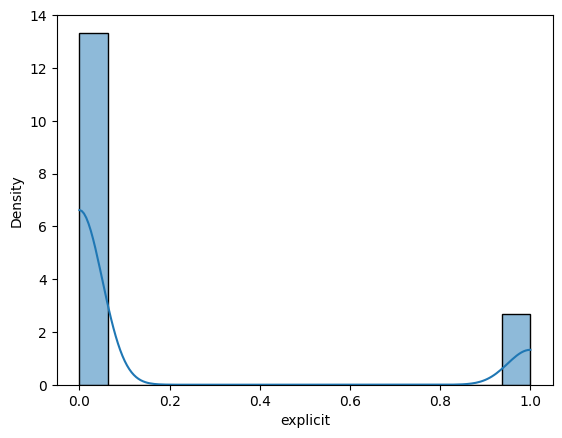

In [4]:
sns.histplot(tracks_data['explicit'], kde=True, stat='density')

#### Wnioski

Widać niezbalansowane klasy atrybutu, natomiast nie powinno mieć to wpływu na opracowywany model, ponieważ atrybut nie niesie ze sobą wartościowych pod kątem zadania informacji.

### Popularity

<Axes: xlabel='popularity', ylabel='Density'>

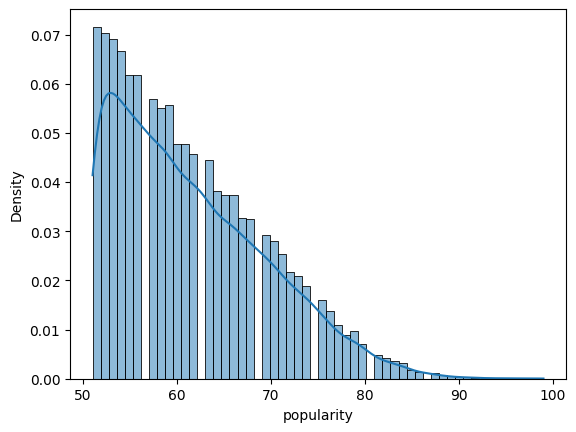

In [5]:
sns.histplot(tracks_data['popularity'], kde=True, stat='density')

<Axes: xlabel='popularity'>

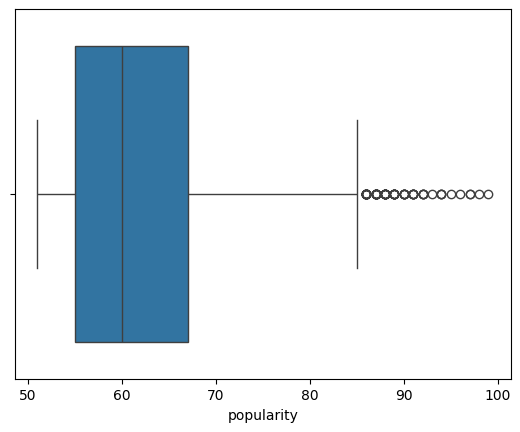

In [6]:
sns.boxplot(x=tracks_data['popularity'])

#### Wnioski

Jest to kluczowy atrybut dla modelu. Rozkład atrubutu jest nieregularny i ma wiele elementów odstających, które mogą być kluczowe przy modelowaniu. Nie moża usunąć elementów z największą popularnością, ponieważ to one właśnie powinny trafiać do playlist. Również z wcześniejszej analizy wynika, że atrybut cierpi na braki danych - możliwe, że widać to też poprzez brakujące słupki na histogramie. 

Potencjalne braki danych może również sygnalizować brak utowrów o popularności mniejszej niż 51.

### Duration ms

<Axes: xlabel='duration_ms', ylabel='Density'>

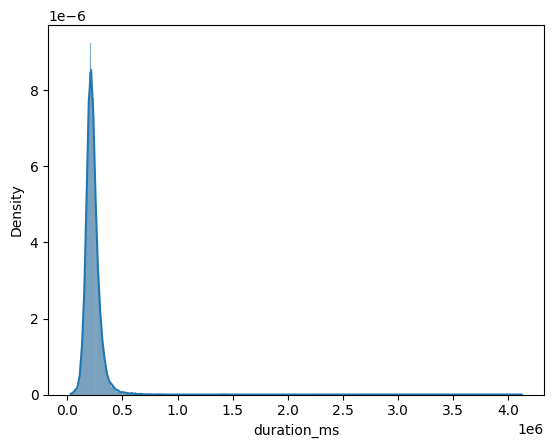

In [7]:
sns.histplot(tracks_data['duration_ms'], kde=True, stat='density')

<Axes: xlabel='duration_ms'>

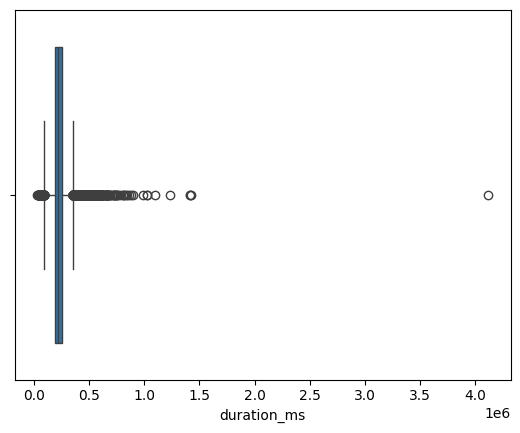

In [8]:
sns.boxplot(x=tracks_data['duration_ms'])

#### Wnioski

Jest wiele elementów odstających, ale nie są one ważne. Model powinien nauczyć się przypisywać im negatywną klasę i nie brać do playlisty. Nie chcemy utworów w playlistcie, które nie będą pasować długością do reszty.

### Danceability

<Axes: xlabel='danceability', ylabel='Density'>

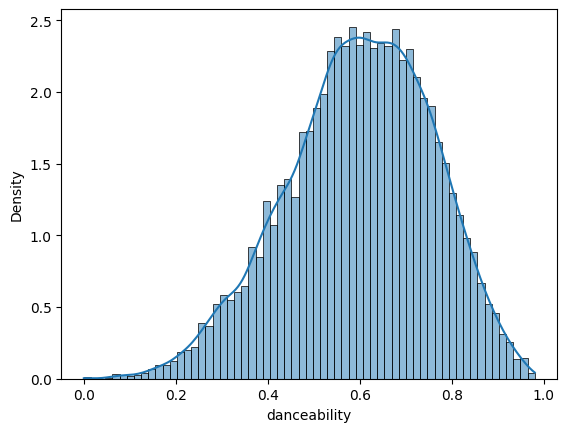

In [9]:
sns.histplot(tracks_data['danceability'], kde=True, stat='density')

<Axes: xlabel='danceability'>

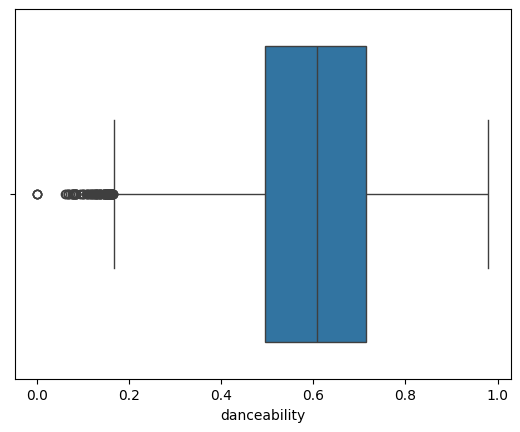

In [10]:
sns.boxplot(x=tracks_data['danceability'])

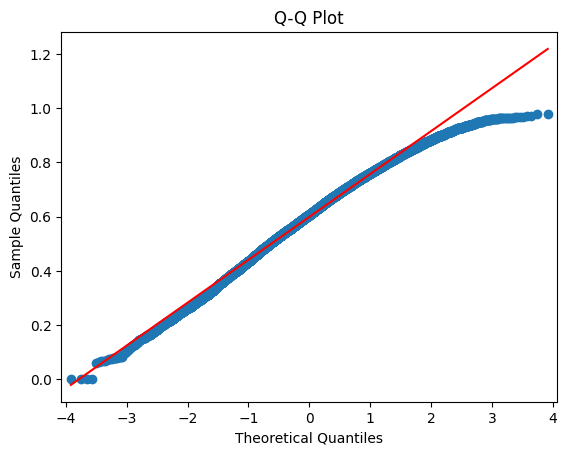

In [11]:
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

# Assuming 'df' is your DataFrame and 'variable' is the column of interest
sm.qqplot(tracks_data['danceability'], line='s')  # 's' indicates standardized line
plt.title('Q-Q Plot')
plt.show()


#### Wnioski

Atrybut ma rozkład zbliżony do rozkładu normalnego, dzięki czemu może być użyteczny przy modelowaniu.

### Energy

<Axes: xlabel='energy', ylabel='Density'>

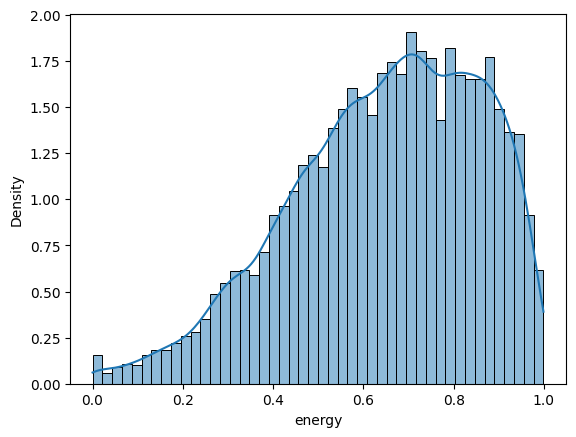

In [12]:
sns.histplot(tracks_data['energy'], kde=True, stat='density')

<Axes: xlabel='energy'>

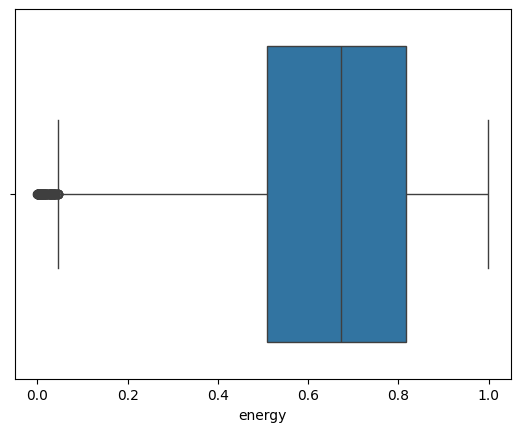

In [13]:
sns.boxplot(x=tracks_data['energy'])

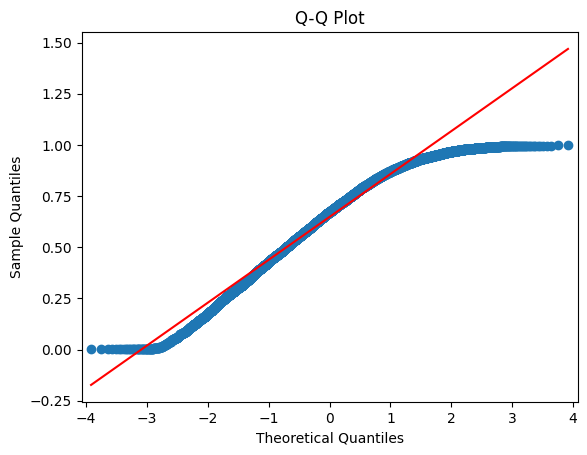

In [14]:
sm.qqplot(tracks_data['energy'], line='s')  # 's' indicates standardized line
plt.title('Q-Q Plot')
plt.show()

#### Wnioski

Atrybut ma rozkład zbliżony do rozkładu normalnego, dzięki czemu może być użyteczny przy modelowaniu. Rozkład jest mocno podobny do rozkładu atrybutu dancebility co daje podstawy do myślenia, że te atrybuty są ze sobą skorelowane.

### Key

<Axes: xlabel='key', ylabel='Density'>

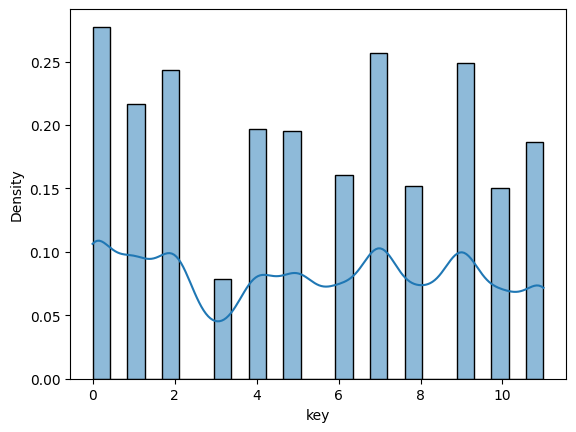

In [15]:
sns.histplot(tracks_data['key'], kde=True, stat='density')

#### Wnioski

Atrybut dyskretny, którego użyteczność do tworzenia algorytmu tworzącego playlisty nie jest widoczna na pierwszy rzut oka.

### Loudness

<Axes: xlabel='loudness', ylabel='Density'>

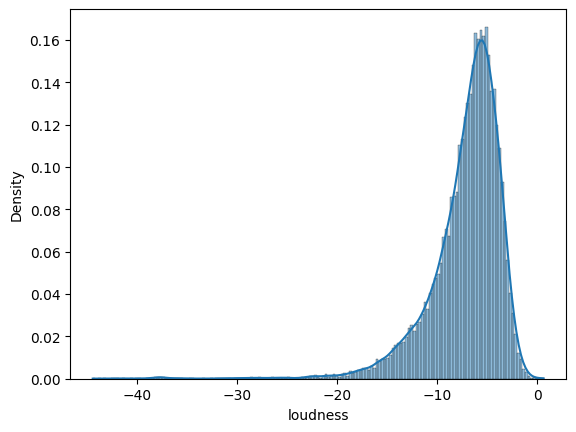

In [16]:
sns.histplot(tracks_data['loudness'], kde=True, stat='density')

<Axes: xlabel='loudness'>

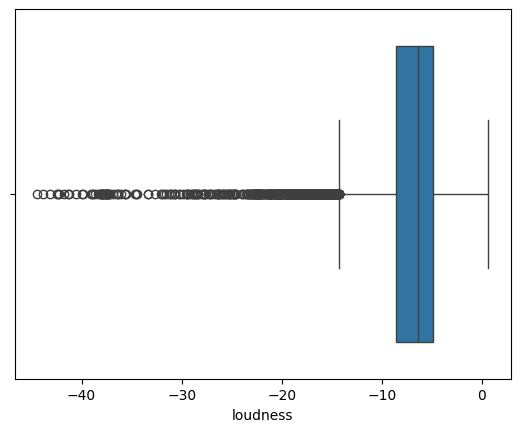

In [17]:
sns.boxplot(x=tracks_data['loudness'])

#### Wnioski

Atrybut ma mocno przesunięty wąsko w prawo rozkład z wieloma elementami odstającymi. Ten nietypowy rozkład trzeba będzie uwzględnić, jeżeli będziemy chcieli go używać przy modelowaniu.

### Speechiness

<Axes: xlabel='speechiness', ylabel='Density'>

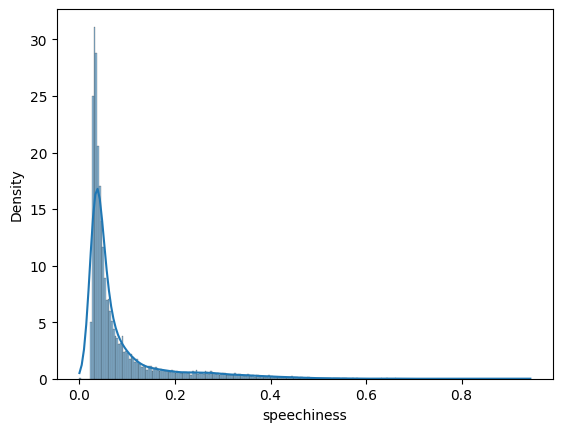

In [18]:
sns.histplot(tracks_data['speechiness'], kde=True, stat='density')

<Axes: xlabel='speechiness'>

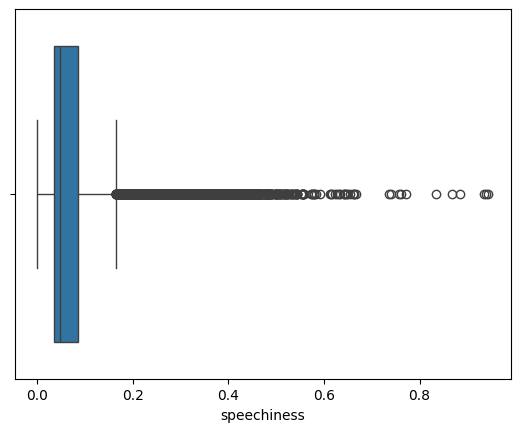

In [19]:
sns.boxplot(x=tracks_data['speechiness'])

#### Wnioski

Atrybut ma mocno przesunięty wąsko w lewo rozkład z wieloma elementami odstającymi. Dla większości przykładów wartość tego atrybutu nie przekracza 0.1. Ten nietypowy rozkład trzeba będzie uwzględnić, jeżeli będziemy chcieli go używać przy modelowaniu.

### Acousticness

<Axes: xlabel='acousticness', ylabel='Density'>

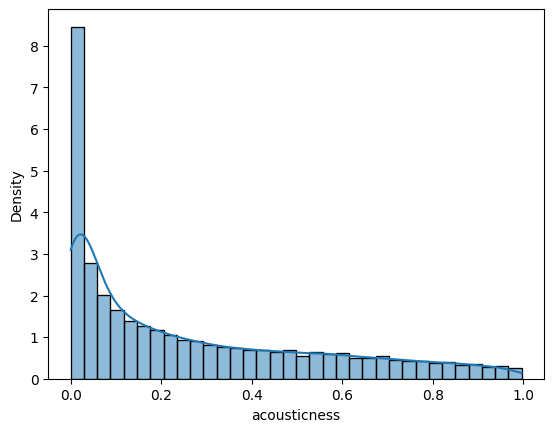

In [20]:
sns.histplot(tracks_data['acousticness'], kde=True, stat='density')

<Axes: xlabel='acousticness'>

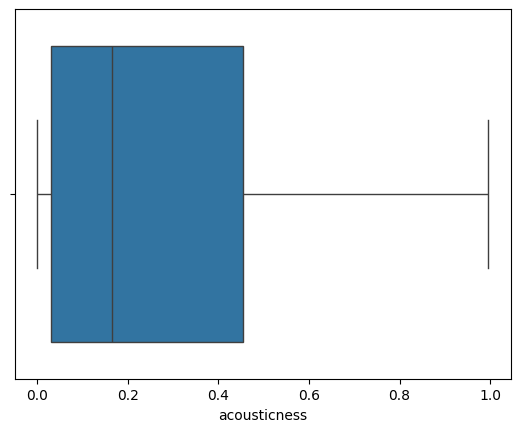

In [21]:
sns.boxplot(x=tracks_data['acousticness'])

#### Wnioski

Atrybut ma mocno przesunięty w prawo rozkład z wieloma elementami odstającymi. Dla większości przykładów wartość tego atrybutu nie przekracza 0.1. Ten nietypowy rozkład trzeba będzie uwzględnić, jeżeli będziemy chcieli go używać przy modelowaniu. Przypomina mocno przesunięty w lewo rozkład Cauchy’ego.

### Instrumentalness

(0.0, 1.0)

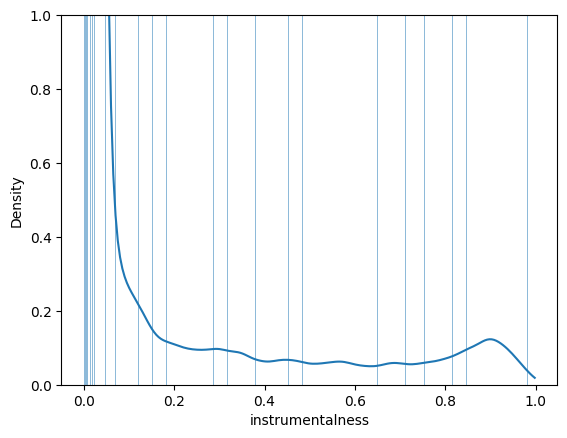

In [35]:
sns.histplot(tracks_data['instrumentalness'], kde=True, stat='density')
plt.ylim(bottom=0, top=1)

<Axes: xlabel='instrumentalness'>

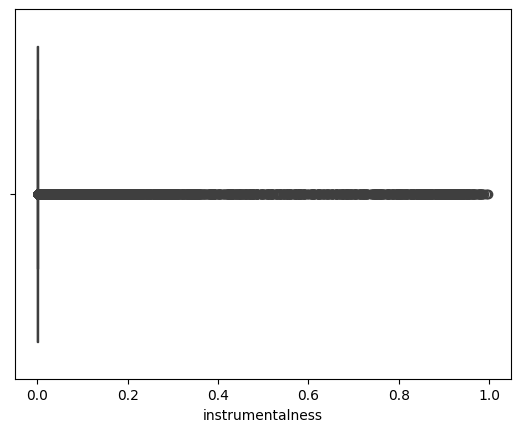

In [23]:
sns.boxplot(x=tracks_data['instrumentalness'])


#### Wnioski

Wstępna analiza pokazała, że atrybut posiada rozkład niezbliżony do żadnego innego. Dla większości utworów wartość tego atrybutu jest zbliżona do zera, natomiast liczba utworów, dla których nie jest bliski zeru nie jest pomijalna.

### Liveness

<Axes: xlabel='liveness', ylabel='Density'>

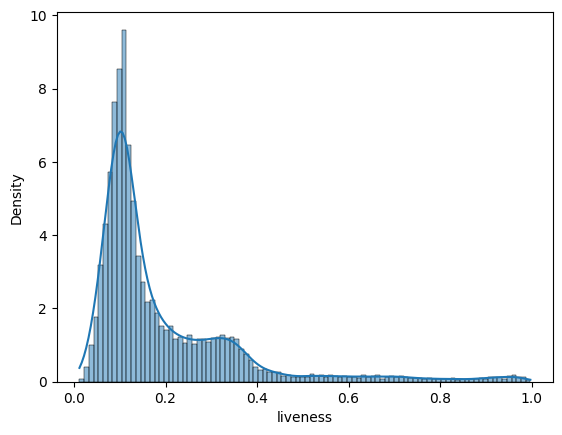

In [24]:
sns.histplot(tracks_data['liveness'], kde=True, stat='density')

<Axes: xlabel='liveness'>

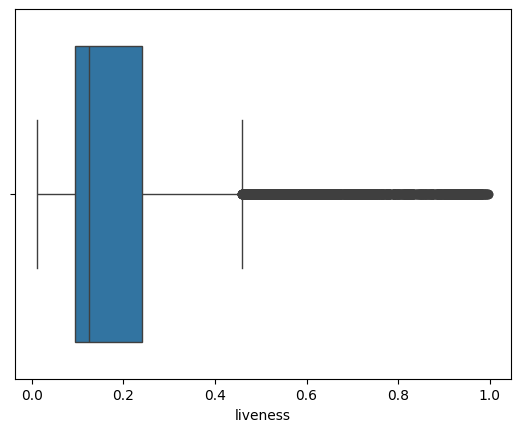

In [25]:
sns.boxplot(x=tracks_data['liveness'])

#### Wnioski

Atrybut ma mocno przesunięty w lewo rozkład z wieloma elementami odstającymi. Średnia wartość tego atrybutu to 0.19. Ten nietypowy rozkład trzeba będzie uwzględnić, jeżeli będziemy chcieli go używać przy modelowaniu. Przypomina mocno przesunięty w lewo rozkład Cauchy’ego.

### Valence

<Axes: xlabel='valence', ylabel='Density'>

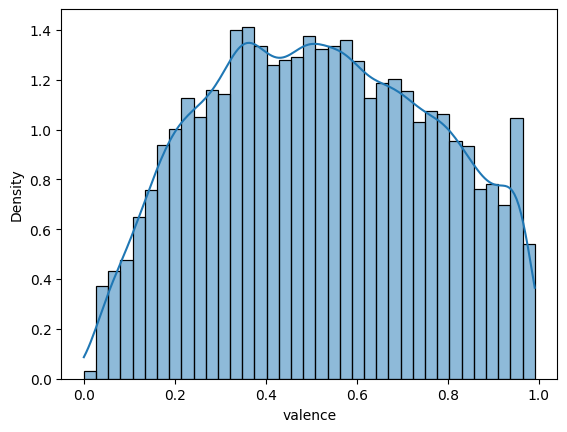

In [26]:
sns.histplot(tracks_data['valence'], kde=True, stat='density')

<Axes: xlabel='valence'>

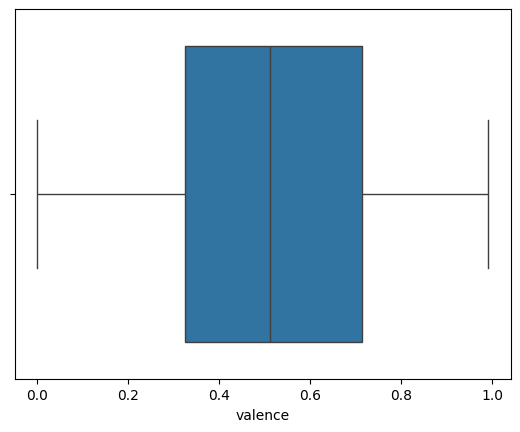

In [27]:
sns.boxplot(x=tracks_data['valence'])

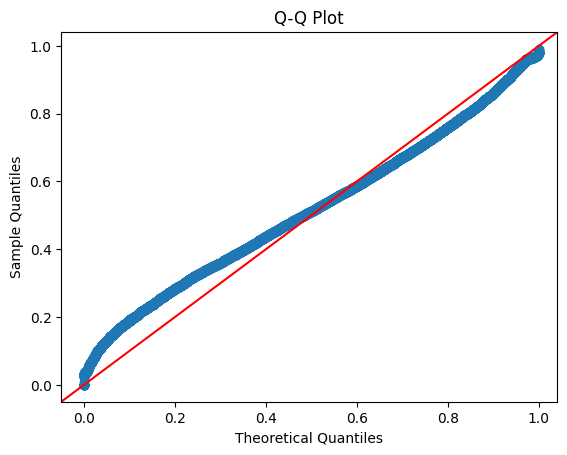

In [28]:
import scipy.stats as stats

sm.qqplot(tracks_data['valence'], dist=stats.uniform, line='45')  # 's' indicates standardized line
plt.title('Q-Q Plot')
plt.show()

#### Wnioski

Rozkład jest najbardziej zbliżony do rozkładu jednostajnego ze wszyszytkich rozkładów atrybutów. Dobry rozkład do modelowania.

### Tempo

<Axes: xlabel='tempo', ylabel='Density'>

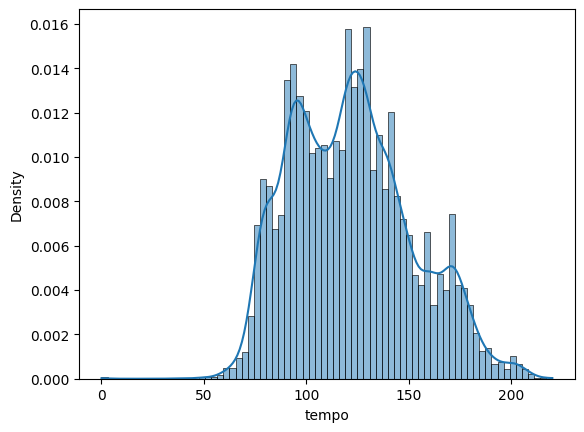

In [29]:
sns.histplot(tracks_data['tempo'], kde=True, stat='density')

<Axes: xlabel='tempo'>

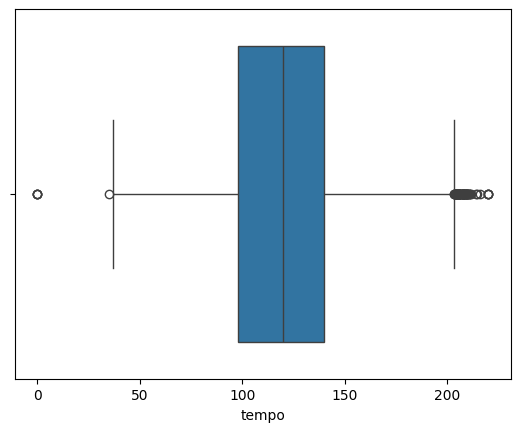

In [30]:
sns.boxplot(x=tracks_data['tempo'])

#### Wnioski

Rozkład jest szeroki co zapewnia dużą reprezentatywność utworów. Średnia wartość około 120 bpm.

## Sprawdzanie zależności zmiennych

#### Dla populairty i duration_ms

In [32]:

numeric_features = tracks_data.select_dtypes(include=['int64', 'float64']).columns
covariance_matrix = tracks_data[numeric_features].corr()
covariance_matrix.style.background_gradient(cmap='coolwarm', axis=None, vmin=-1, vmax=1).format(precision=3)

,popularity,duration_ms,explicit,danceability,energy,key,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
popularity,1.000,-0.098,0.125,0.097,-0.025,-0.011,0.082,0.042,-0.036,-0.070,-0.060,-0.029,0.005
duration_ms,-0.098,1.000,-0.079,-0.209,0.023,0.003,-0.038,-0.093,-0.079,0.084,0.022,-0.187,-0.017
explicit,0.125,-0.079,1.000,0.215,0.045,0.009,0.071,0.446,-0.076,-0.064,-0.009,-0.073,-0.014
danceability,0.097,-0.209,0.215,1.000,0.062,0.026,0.167,0.198,-0.079,-0.179,-0.082,0.455,-0.139
energy,-0.025,0.023,0.045,0.062,1.000,0.023,0.712,0.116,-0.648,-0.136,0.160,0.337,0.172
key,-0.011,0.003,0.009,0.026,0.023,1.000,0.019,0.029,-0.017,-0.004,-0.008,0.033,0.008
loudness,0.082,-0.038,0.071,0.167,0.712,0.019,1.000,0.081,-0.466,-0.368,0.084,0.236,0.142
speechiness,0.042,-0.093,0.446,0.198,0.116,0.029,0.081,1.000,-0.074,-0.078,0.051,0.033,0.049
acousticness,-0.036,-0.079,-0.076,-0.079,-0.648,-0.017,-0.466,-0.074,1.000,0.091,-0.042,-0.150,-0.113
instrumentalness,-0.070,0.084,-0.064,-0.179,-0.136,-0.004,-0.368,-0.078,0.091,1.000,-0.035,-0.155,-0.034


### Wnioski

Z tabeli widać, że skorelowane ze sobą są atrybuty:
- loudness i energy
- acousticness i energy

Umiarkowana korelacja:
- speechiness i explicit
- valence i danceability

Oznacza to, że ogólnie niski poziom skorelowania atrybutów sugeruje, że nie są od siebie zależne, dzieki czemu będą mogły być efektywnie ze sobą używane do zadania modelowania. Jednocześnie brakuje atrybutów, które byłyby skorelowane z atrybutem popularity, co oznacza, że wskazanie atrybutów mogących przewidywać popularność utworu może być wymagające. W związku z tym konieczne jest przeprowadzenie dalszej analizy i obróbki danych.

## Dane o artystach

In [33]:
artists_data = pd.read_json('artists.jsonl', lines=True)
artists_data.describe(include='all')

,id,name,genres
count,1667,1667,1590
unique,1577,1667,1296
top,-1,BEAM,"[latin, latin hip hop, reggaeton, reggaeton fl..."
freq,91,1,15


### Wnioski

Braki danych - niektórzy artyści nie mają przypisanych do siebie gatunków muzyki, co może utrudnić zadanie modelowania.

## Dane o użytkownikach

In [37]:
users_data = pd.read_json('users.jsonl', lines=True)
users_data.describe(include='all')

,user_id,name,city,street,favourite_genres,premium_user,id
count,100.000000,100,100,100,97,97.000000,4.0
unique,NaN,100,7,100,97,NaN,NaN
top,NaN,Dominik Martyka,Gdynia,ul. Plater 80/83,"[corrido, post-teen pop, canadian pop]",NaN,NaN
freq,NaN,1,23,1,1,NaN,NaN
mean,850.500000,NaN,NaN,NaN,NaN,0.154639,-1.0
std,29.011492,NaN,NaN,NaN,NaN,0.363439,0.0
min,801.000000,NaN,NaN,NaN,NaN,0.000000,-1.0
25%,825.750000,NaN,NaN,NaN,NaN,0.000000,-1.0
50%,850.500000,NaN,NaN,NaN,NaN,0.000000,-1.0
75%,875.250000,NaN,NaN,NaN,NaN,0.000000,-1.0


In [ ]:
users_data

,user_id,name,city,street,favourite_genres,premium_user,id
0,801,Dominik Paździora,Wrocław,aleja Jabłoniowa 55/02,"[dance pop, latin, hard rock]",0.0,NaN
1,802,Justyna Mszyca,Poznań,ul. Krótka 710,"[reggaeton, latin arena pop, modern rock]",0.0,NaN
2,803,Kornelia Witka,Gdynia,al. Kościuszki 587,"[rap, art rock, rock]",0.0,NaN
3,804,Jędrzej Kotala,Gdynia,pl. Kossaka 97/86,"[mexican pop, contemporary country, psychedeli...",0.0,NaN
4,805,Karol Kleban,Kraków,ul. Tulipanowa 861,"[rock, adult standards, permanent wave]",0.0,NaN
...,...,...,...,...,...,...,...
95,896,Leon Mycek,Gdynia,pl. Turkusowa 31/61,"[electropop, tropical, k-pop]",0.0,NaN
96,897,Wojciech Boguta,Gdynia,plac Stawowa 33,"[neo mellow, pop rock, pop urbaine]",0.0,NaN
97,898,Patryk Drobny,Szczecin,plac Tuwima 513,"[pop urbaine, pop rap, country]",0.0,NaN
98,899,Konstanty Drozdowicz,Wrocław,ul. Niepodległości 793,"[alternative metal, psychedelic rock, latin ar...",0.0,NaN


### Wnioski

Jest bardzo mała liczba użytkowników. Id użytkowników zaczyna się od 801, co sugeruje, że jest więcej danych.

## Podsumowanie

#### Braki w danych

Brakuje ważnych atrybutów dla utworów - popularity i id artysty. Przysłana liczba użytkowników nie jest wystarczająca do właściwego zamodelowania problemu.

Brak danych o sesjach użytkowników.

#### Dobre atrybuty

Dostarczone atrybuty utworów są mało ze sobą skorelowane, a większość z nich posiada sensowny rozkład, który będzie można wykorzystać do analizy. Warto jednak zaznaczyć, że brakuje atrybutów skorelowanych z atrybutem popularity. Oznacza to, że przewidzenie, które utwory będą popularne jedynie na podstawie danych o ich charakterze, może być wymagające. W związku z tym nie możemy na obecnym etapie prac jednoznacznie stwierdzić, czy dostarczone dane, w tym zmienne wejściowe, będą wystarczające do realizacji zadania modelowania.

#### Problemy z atrybutami

Niektóre atrybuty mają bardzo wąski rozkład z wieloma elementami odstającymi. Atrybut popularity dziwnie ucina się przy wartości 51, tak jakby brakowało lewej połowy wykresu.



